In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow version:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices("GPU")) > 0)
print("Libraries imported successfully!")


TensorFlow version: 2.21.0
GPU available: True
Libraries imported successfully!


In [ ]:
from google.colab import files

uploaded = files.upload()


Saving Dig-MNIST.csv to Dig-MNIST.csv
Saving sample_submission.csv to sample_submission.csv
Saving test.csv to test.csv
Saving train.csv to train.csv


In [ ]:
import os
import pandas as pd

# Display the files available in Colab
print("Files available in /content:")
print(os.listdir("/content"))

# Correct paths: files were uploaded directly to /content
train_path = "/content/train.csv"
dig_path = "/content/Dig-MNIST.csv"
test_path = "/content/test.csv"
submission_path = "/content/sample_submission.csv"

# Load the datasets
train_df = pd.read_csv(train_path)
dig_df = pd.read_csv(dig_path)
test_df = pd.read_csv(test_path)
sample_submission_df = pd.read_csv(submission_path)

# Display dataset sizes
print("\nTRAIN DATASET SHAPE:", train_df.shape)
print("DIG-MNIST DATASET SHAPE:", dig_df.shape)
print("TEST DATASET SHAPE:", test_df.shape)
print("SAMPLE SUBMISSION SHAPE:", sample_submission_df.shape)

# Preview the data
print("\nTraining dataset preview:")
display(train_df.head())

print("\nDig-MNIST dataset preview:")
display(dig_df.head())



Files available in /content:
['.config', 'sample_submission.csv', 'test.csv', 'train.csv', 'Dig-MNIST.csv', 'sample_data']

TRAIN DATASET SHAPE: (60000, 785)
DIG-MNIST DATASET SHAPE: (10240, 785)
TEST DATASET SHAPE: (5000, 785)
SAMPLE SUBMISSION SHAPE: (5000, 2)

Training dataset preview:


,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0



Dig-MNIST dataset preview:


,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


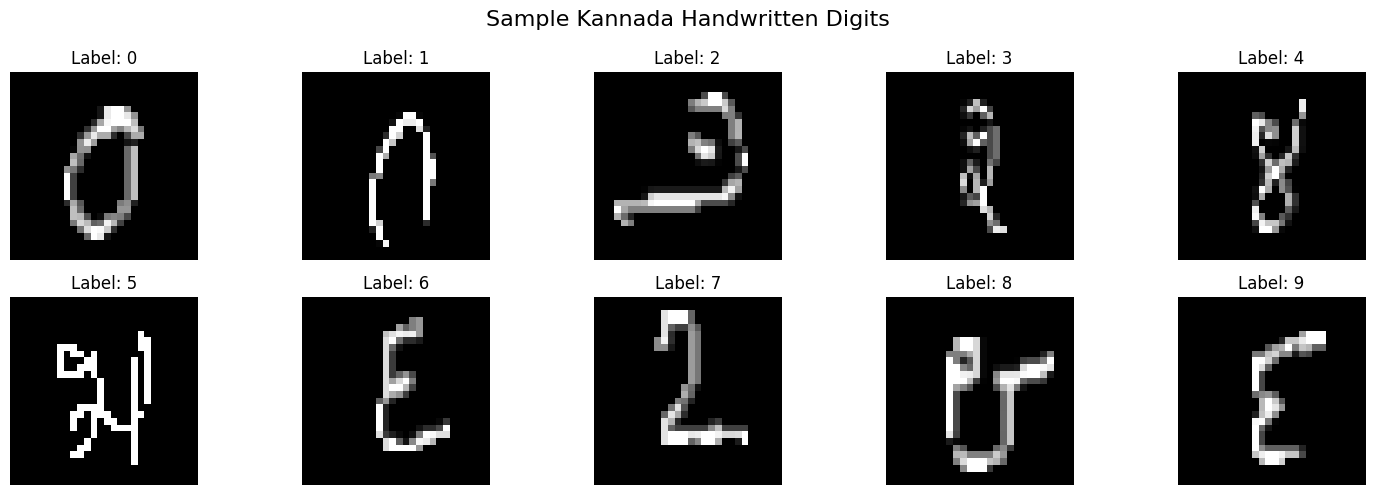

Number of classes: 10

Images per class:
label
0    6000
1    6000
2    6000
3    6000
4    6000
5    6000
6    6000
7    6000
8    6000
9    6000
Name: count, dtype: int64


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Separate labels and pixel values
X_preview = train_df.drop(columns=["label"]).values
y_preview = train_df["label"].values

# Display 10 sample images
plt.figure(figsize=(15, 5))

for i in range(10):
    image = X_preview[i].reshape(28, 28)

    plt.subplot(2, 5, i + 1)
    plt.imshow(image, cmap="gray")
    plt.title(f"Label: {y_preview[i]}")
    plt.axis("off")

plt.suptitle("Sample Kannada Handwritten Digits", fontsize=16)
plt.tight_layout()
plt.show()

# Check label distribution
print("Number of classes:", train_df["label"].nunique())
print("\nImages per class:")
print(train_df["label"].value_counts().sort_index())


In [ ]:

from sklearn.model_selection import train_test_split
import numpy as np

# Separate labels and pixel values
X = train_df.drop(columns=["label"]).to_numpy(dtype=np.float32)
y = train_df["label"].to_numpy(dtype=np.int64)

# Normalize pixel values to the range 0-1
X = X / 255.0

# Reshape images to 28 x 28 grayscale
X = X.reshape(-1, 28, 28, 1)

# Split into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training images:", X_train.shape)
print("Validation images:", X_val.shape)
print("Training labels:", y_train.shape)
print("Validation labels:", y_val.shape)
print("Pixel range:", X_train.min(), "to", X_train.max())

print("Pixel range:", X_train.min(), "to", X_train.max())


Training images: (48000, 28, 28, 1)
Validation images: (12000, 28, 28, 1)
Training labels: (48000,)
Validation labels: (12000,)
Pixel range: 0.0 to 1.0
Pixel range: 0.0 to 1.0


In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.random.set_seed(42)

model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.BatchNormalization(),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(10, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       802,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 897,802 (3.42 MB)

 Trainable params: 897,354 (3.42 MB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

callbacks = [
    EarlyStopping(
        monitor="val_accuracy",
        patience=3,
        restore_best_weights=True
    ),
    ModelCheckpoint(
        "/content/best_kannada_cnn.keras",
        monitor="val_accuracy",
        save_best_only=True
    )
]

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=128,
    callbacks=callbacks,
    verbose=1
)

print("CNN training completed!")


Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 16s 15ms/step - accuracy: 0.9666 - loss: 0.1152 - val_accuracy: 0.9621 - val_loss: 0.1210
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9898 - loss: 0.0346 - val_accuracy: 0.9914 - val_loss: 0.0352
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9923 - loss: 0.0259 - val_accuracy: 0.9945 - val_loss: 0.0238
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9930 - loss: 0.0243 - val_accuracy: 0.9931 - val_loss: 0.0309
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9945 - loss: 0.0204 - val_accuracy: 0.9939 - val_loss: 0.0326
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9953 - loss: 0.0159 - val_accuracy: 0.9946 - val_loss: 0.0246
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.9960 - loss: 0.0130 - val_accuracy: 0.9936 - val_loss: 0.0210
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9965 - loss: 0.0107 - val_accuracy: 

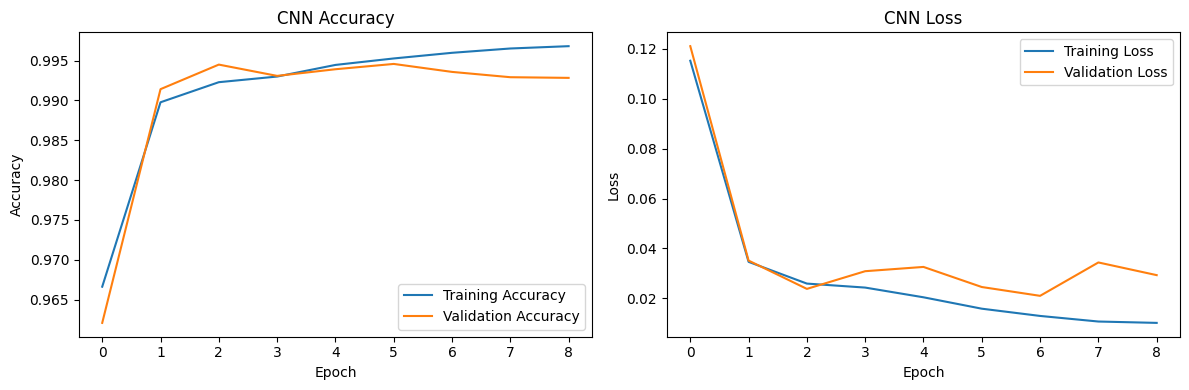

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

# Predict validation labels
y_val_prob = model.predict(X_val, verbose=0)
y_val_pred = np.argmax(y_val_prob, axis=1)

# Calculate metrics
val_accuracy = accuracy_score(y_val, y_val_pred)
val_f1 = f1_score(y_val, y_val_pred, average="weighted")

print("VALIDATION RESULTS")
print("------------------")
print(f"Accuracy: {val_accuracy:.4f}")
print(f"Weighted F1-score: {val_f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred, digits=4))


VALIDATION RESULTS
------------------
Accuracy: 0.9946
Weighted F1-score: 0.9946

Classification Report:
              precision    recall  f1-score   support

           0     0.9950    0.9908    0.9929      1200
           1     0.9934    0.9967    0.9950      1200
           2     0.9983    0.9992    0.9988      1200
           3     0.9852    0.9992    0.9921      1200
           4     0.9983    0.9958    0.9971      1200
           5     0.9950    1.0000    0.9975      1200
           6     0.9900    0.9917    0.9908      1200
           7     0.9949    0.9825    0.9887      1200
           8     1.0000    0.9967    0.9983      1200
           9     0.9958    0.9933    0.9946      1200

    accuracy                         0.9946     12000
   macro avg     0.9946    0.9946    0.9946     12000
weighted avg     0.9946    0.9946    0.9946     12000



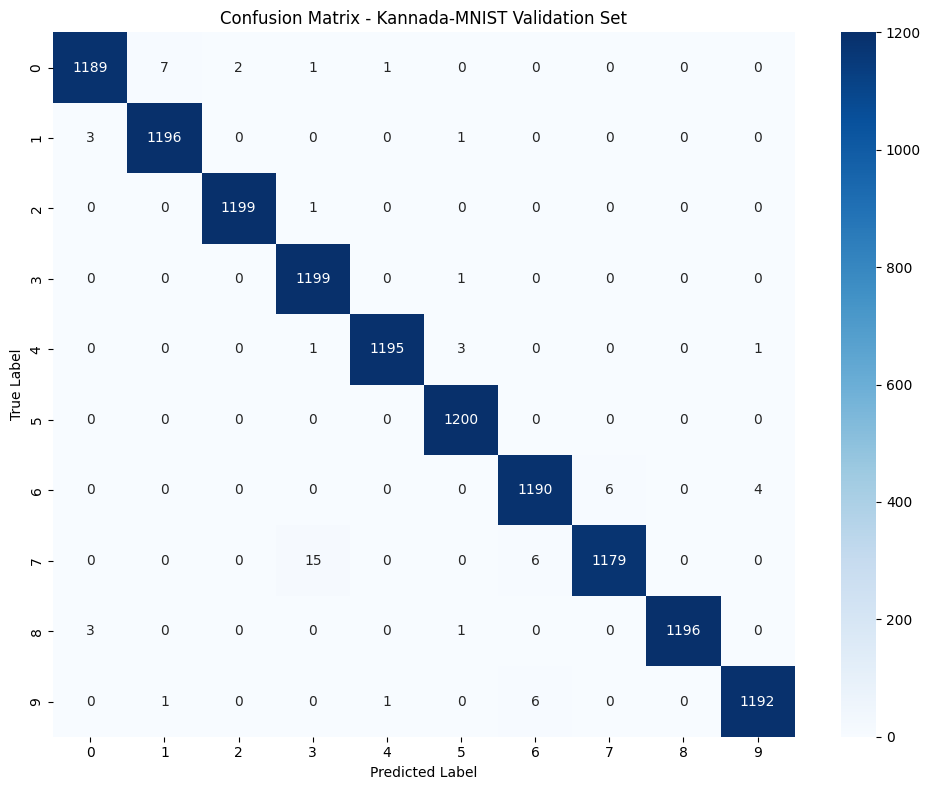

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_val, y_val_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=range(10),
    yticklabels=range(10)
)

plt.title("Confusion Matrix - Kannada-MNIST Validation Set")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()


In [ ]:
X_dig = dig_df.drop(columns=["label"]).to_numpy(dtype=np.float32)
y_dig = dig_df["label"].to_numpy(dtype=np.int64)

X_dig = X_dig / 255.0
X_dig = X_dig.reshape(-1, 28, 28, 1)

y_dig_prob = model.predict(X_dig, batch_size=128, verbose=1)
y_dig_pred = np.argmax(y_dig_prob, axis=1)

dig_accuracy = accuracy_score(y_dig, y_dig_pred)
dig_f1 = f1_score(y_dig, y_dig_pred, average="weighted")

print("\nDIG-MNIST RESULTS")
print("-----------------")
print(f"Accuracy: {dig_accuracy:.4f}")
print(f"Weighted F1-score: {dig_f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_dig, y_dig_pred, digits=4))


80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step

DIG-MNIST RESULTS
-----------------
Accuracy: 0.8006
Weighted F1-score: 0.7992

Classification Report:
              precision    recall  f1-score   support

           0     0.8410    0.7334    0.7835      1024
           1     0.9059    0.7900    0.8440      1024
           2     0.7238    0.9111    0.8067      1024
           3     0.8494    0.6006    0.7037      1024
           4     0.8679    0.8662    0.8671      1024
           5     0.7198    0.9658    0.8249      1024
           6     0.6708    0.7441    0.7056      1024
           7     0.8727    0.6963    0.7746      1024
           8     0.9123    0.8027    0.8540      1024
           9     0.7699    0.8955    0.8280      1024

    accuracy                         0.8006     10240
   macro avg     0.8134    0.8006    0.7992     10240
weighted avg     0.8134    0.8006    0.7992     10240



In [ ]:
# Check the test dataset
print("Test dataset shape:", test_df.shape)
print("Test dataset columns:", test_df.columns[:5].tolist())

# Remove label or ID columns if present
X_test_df = test_df.drop(
    columns=["label", "id", "ID", "index"],
    errors="ignore"
)

# Keep only the 784 pixel columns
if X_test_df.shape[1] != 784:
    X_test_df = X_test_df.iloc[:, -784:]

# Convert to NumPy
X_test = X_test_df.to_numpy(dtype=np.float32)

# Normalize pixel values
if X_test.max() > 1:
    X_test = X_test / 255.0

# Reshape into 28x28 grayscale images
X_test = X_test.reshape(-1, 28, 28, 1)

print("Processed test shape:", X_test.shape)

# Predict
test_probabilities = model.predict(
    X_test, batch_size=128, verbose=1
)

test_predictions = np.argmax(test_probabilities, axis=1)

print("Number of predictions:", len(test_predictions))
print("First 20 predictions:", test_predictions[:20])

print("Predicted classes:", np.unique(test_predictions))


Test dataset shape: (5000, 785)
Test dataset columns: ['id', 'pixel0', 'pixel1', 'pixel2', 'pixel3']
Processed test shape: (5000, 28, 28, 1)
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 56ms/step
Number of predictions: 5000
First 20 predictions: [3 0 2 6 7 7 1 9 3 4 8 8 1 7 8 1 5 1 5 9]
Predicted classes: [0 1 2 3 4 5 6 7 8 9]


In [ ]:
submission = sample_submission_df.copy()

print("Sample submission shape:", submission.shape)
print("Sample submission columns:", submission.columns.tolist())

# Replace the label column with predictions
submission["label"] = test_predictions

submission.to_csv(
    "/content/kannada_mnist_submission.csv",
    index=False
)

print("Submission created successfully!")
display(submission.head())
print("Final shape:", submission.shape)


Sample submission shape: (5000, 2)
Sample submission columns: ['id', 'label']
Submission created successfully!


,id,label
0,0,3
1,1,0
2,2,2
3,3,6
4,4,7


Final shape: (5000, 2)


In [ ]:
import os
import json
import matplotlib.pyplot as plt
from google.colab import files

# Create a folder for project outputs
output_dir = "/content/Kannada_MNIST_Results"
os.makedirs(output_dir, exist_ok=True)

# Save the trained model
model.save(f"{output_dir}/kannada_mnist_cnn.keras")

# Save the accuracy and loss graph
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.savefig(f"{output_dir}/accuracy_loss_graph.png", dpi=300)
plt.close()

# Save the confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Kannada-MNIST Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.savefig(f"{output_dir}/confusion_matrix.png", dpi=300)
plt.close()

# Save evaluation metrics
results = {
    "validation_accuracy": float(val_accuracy),
    "validation_weighted_f1": float(val_f1),
    "dig_mnist_accuracy": float(dig_accuracy),
    "dig_mnist_weighted_f1": float(dig_f1)
}

with open(f"{output_dir}/evaluation_results.json", "w") as f:
    json.dump(results, f, indent=4)

# Copy submission into the output folder
import shutil
shutil.copy(
    "/content/kannada_mnist_submission.csv",
    f"{output_dir}/kannada_mnist_submission.csv"
)

# Compress everything into one ZIP file
shutil.make_archive(
    "/content/Kannada_MNIST_Results",
    "zip",
    output_dir
)

print("All project outputs saved!")
print("ZIP file: /content/Kannada_MNIST_Results.zip")



All project outputs saved!
ZIP file: /content/Kannada_MNIST_Results.zip


In [ ]:

files.download("/content/Kannada_MNIST_Results.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>